<a href="https://colab.research.google.com/github/tevfikaytekin/CMP2003/blob/main/recursion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Recursion


## Introduction to Recursion

Recursion occurs when a function calls itself to solve a smaller instance of the same problem. Every recursive function needs two parts:
- **Base Case:** The condition under which the recursion stops.
- **Recursive Case:** The part where the function calls itself with modified parameters.

### Example: Calculating Factorial
Let's write a simple C++ program to compute the factorial of a number.

In [ ]:
%%writefile factorial.cpp
#include <iostream>
using namespace std;

// Recursive function to calculate factorial
int factorial(int n) {
    // Base case
    if (n <= 1) {
        return 1;
    }
    // Recursive case
    return n * factorial(n - 1);
}

int main() {
    int num = 5;
    cout << "Factorial of " << num << " is: " << factorial(num) << endl;
    return 0;
}


Overwriting factorial.cpp


In [ ]:
!g++ factorial.cpp -o factorial && ./factorial

Factorial of 5 is: 120


### Example 2: The Fibonacci Sequence
While factorial has a single recursive call, the Fibonacci sequence requires two. This is an excellent example for visualizing a **Recursion Tree** and understanding how multiple calls branch out.

*Fibonacci rule:* `F(n) = F(n-1) + F(n-2)`
*Base cases:* `F(0) = 0`, `F(1) = 1`

In [ ]:
%%writefile fibonacci.cpp
#include <iostream>
using namespace std;

// Recursive function for Fibonacci sequence
int fibonacci(int n) {
    // Base cases
    if (n == 0) return 0;
    if (n == 1) return 1;

    // Recursive case: two calls!
    return fibonacci(n - 1) + fibonacci(n - 2);
}

int main() {
    int terms = 50;
    cout << "Fibonacci sequence up to " << terms << " terms: ";
    for(int i = 0; i < terms; i++) {
        cout << fibonacci(i) << " ";
    }
    cout << endl;
    return 0;
}


Overwriting fibonacci.cpp


In [ ]:
!g++ fibonacci.cpp -o fibonacci && ./fibonacci

^C


### Visualizing the Recursion Tree
To truly understand how the Fibonacci recursion works, we can visualize the **Call Stack / Recursion Tree** by adding an indentation parameter that increases with each recursive call depth. This allows us to see exactly how the calls branch out.

In [ ]:
%%writefile fibonacci_tree.cpp
#include <iostream>
#include <string>
using namespace std;

// Recursive function with depth tracking for visualization
int fibonacci_tree(int n, int depth = 0) {
    // Create indentation based on the current depth
    string indent(depth * 4, ' ');

    // Print the current function call
    cout << indent << "fibonacci(" << n << ") called" << endl;

    // Base cases
    if (n == 0) return 0;
    if (n == 1) return 1;

    // Recursive calls (branching left and right)
    int left = fibonacci_tree(n - 1, depth + 1);
    int right = fibonacci_tree(n - 2, depth + 1);

    return left + right;
}

int main() {
    cout << "Recursion Tree for fibonacci(5):\n";
    cout << "--------------------------------\n";
    int result = fibonacci_tree(5);
    cout << "--------------------------------\n";
    cout << "Result: " << result << endl;
    return 0;
}


Overwriting fibonacci_tree.cpp


In [ ]:
!g++ fibonacci_tree.cpp -o fibonacci_tree && ./fibonacci_tree

Recursion Tree for fibonacci(5):
--------------------------------
fibonacci(5) called
    fibonacci(4) called
        fibonacci(3) called
            fibonacci(2) called
                fibonacci(1) called
                fibonacci(0) called
            fibonacci(1) called
        fibonacci(2) called
            fibonacci(1) called
            fibonacci(0) called
    fibonacci(3) called
        fibonacci(2) called
            fibonacci(1) called
            fibonacci(0) called
        fibonacci(1) called
--------------------------------
Result: 5


### The Problem: Exponential Time Complexity $O(2^n)$
Look closely at the recursion tree above for `fibonacci(4)`. Notice how `fibonacci(2)` is calculated twice, and `fibonacci(1)` is calculated three times? As `n` grows, the number of overlapping subproblems grows exponentially. This gives our basic recursive algorithm a time complexity of $O(2^n)$ (more precisely, bounded by the golden ratio $O(1.618^n)$).

If you try to calculate `fibonacci(50)` with the naive method, it might take minutes or even hours to finish!

### The Solution: Memoization (Top-Down Dynamic Programming)
We can solve this problem while keeping our elegant recursive structure by using **Memoization**. We simply use an array (or vector) to "remember" the results of function calls we've already made. If we ask for a Fibonacci number we've already calculated, we return the cached result in $O(1)$ time. This reduces the overall time complexity to $O(n)$.

In [ ]:
%%writefile fibonacci_memo.cpp
#include <iostream>
#include <vector>
using namespace std;

// Memoization table to store previously calculated values
vector<long> memo;

// Optimized Recursive function for Fibonacci using Memoization
long long fibonacci_optimized(int n) {
    // Base cases
    if (n == 0) return 0;
    if (n == 1) return 1;

    // Check if we have already calculated this value
    if (memo[n] != -1) {
        return memo[n]; // Return cached value instantly
    }

    // Otherwise, calculate it, store it in the memo table, and return it
    memo[n] = fibonacci_optimized(n - 1) + fibonacci_optimized(n - 2);
    return memo[n];
}

int main() {
    int terms = 10;
    // Initialize memo table with -1 (indicating uncalculated states) for 'terms + 1' elements
    memo.assign(terms + 1, -1);

    cout << "Optimized Fibonacci up to " << terms << " terms:\n";
    for(int i = 0; i <= terms; i++) {
        cout << fibonacci_optimized(i) << " ";
    }
    cout << endl;

    return 0;
}


Writing fibonacci_memo.cpp


In [ ]:
!g++ fibonacci_memo.cpp -o fibonacci_memo && ./fibonacci_memo

Optimized Fibonacci up to 10 terms:
0 1 1 2 3 5 8 13 21 34 55 


### Performance Comparison: Naive vs. Memoized
To demonstrate how dramatic the difference is for larger values, let's write a program that measures the actual execution time (in milliseconds) for both implementations when calculating `fibonacci(40)`.

In [ ]:
%%writefile fibonacci_compare.cpp
#include <iostream>
#include <vector>
#include <chrono>
using namespace std;

// Naive recursive Fibonacci
long long fibonacci_naive(int n) {
    if (n == 0) return 0;
    if (n == 1) return 1;
    return fibonacci_naive(n - 1) + fibonacci_naive(n - 2);
}

// Memoized Fibonacci
vector<long long> memo;
long long fibonacci_memoized(int n) {
    if (n == 0) return 0;
    if (n == 1) return 1;
    if (memo[n] != -1) return memo[n];
    memo[n] = fibonacci_memoized(n - 1) + fibonacci_memoized(n - 2);
    return memo[n];
}

int main() {
    int n = 40;

    cout << "Calculating fibonacci(" << n << ")...\n\n";

    // 1. Measure Naive
    auto start = chrono::high_resolution_clock::now();
    long long result_naive = fibonacci_naive(n);
    auto end = chrono::high_resolution_clock::now();
    chrono::duration<double, milli> duration_naive = end - start;
    cout << "[Naive Recursive] Result: " << result_naive
         << " | Time: " << duration_naive.count() << " ms\n";

    // 2. Measure Memoized
    memo.assign(n + 1, -1);
    start = chrono::high_resolution_clock::now();
    long long result_memo = fibonacci_memoized(n);
    end = chrono::high_resolution_clock::now();
    chrono::duration<double, milli> duration_memo = end - start;
    cout << "[Memoized Recursive] Result: " << result_memo
         << " | Time: " << duration_memo.count() << " ms\n";

    return 0;
}

Writing fibonacci_compare.cpp


In [ ]:
!g++ -O3 fibonacci_compare.cpp -o fibonacci_compare && ./fibonacci_compare

Calculating fibonacci(40)...

[Naive Recursive] Result: 102334155 | Time: 225.903 ms
[Memoized Recursive] Result: 102334155 | Time: 0.000519 ms


### Example 3: Sum of an Array (Recursive Iteration)
Recursion isn't just for mathematical formulas; it can also replace loops. Let's see how we can calculate the sum of an array using recursion by breaking the array down into the `first element + sum of the rest`.

In [ ]:
%%writefile array_sum.cpp
#include <iostream>
using namespace std;

// Recursive function to find the sum of an array
int arraySum(int arr[], int n) {
    // Base case: if array is empty, sum is 0
    if (n <= 0) {
        return 0;
    }
    // Recursive case: last element + sum of the remaining array
    return arr[n - 1] + arraySum(arr, n - 1);
}

int main() {
    int arr[] = {2, 4, 6, 8, 10};
    int n = sizeof(arr) / sizeof(arr[0]);

    cout << "The sum of the array is: " << arraySum(arr, n) << endl;
    return 0;
}


Writing array_sum.cpp


In [ ]:
!g++ array_sum.cpp -o array_sum && ./array_sum

The sum of the array is: 30


---
## Advanced Recursion and Backtracking

Backtracking is an algorithmic technique for solving problems recursively by trying to build a solution incrementally, one piece at a time, removing those solutions that fail to satisfy the constraints of the problem at any point in time.

### Example: The N-Queens Problem
Place N chess queens on an N×N chessboard so that no two queens threaten each other.

### Solvability Examples: 3x3 vs 4x4 Boards

Not every $N \times N$ chessboard has a valid placement for $N$ non-attacking queens. Let's look at two specific examples:

#### 1. Unsolvable Case: $3 \times 3$ Board ($N = 3$)
For a $3 \times 3$ board, it is mathematically impossible to place $3$ non-attacking queens.

If we place a queen in the first column, we block its row and diagonals. Regardless of where you try to position the queens in columns 2 and 3, you will find that any valid placement conflicts on rows or diagonals. Thus, a $3 \times 3$ board has **no solution**.

#### 2. Solvable Case: $4 \times 4$ Board ($N = 4$)
For a $4 \times 4$ board, we can find a valid solution. One configuration looks like as below. Here, each row, column, and diagonal contains exactly one queen, making it a **valid solution**.

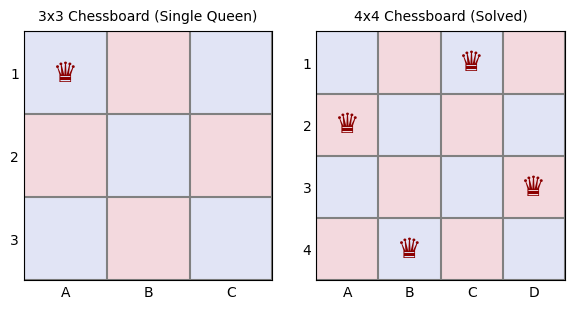

### N-Queens Solution Strategy: Backtracking

The implementation uses a classic **Backtracking** algorithm to solve the N-Queens problem. The core idea is to place queens column by column:

1. **Column-by-Column Placement:** The function `solveNQUtil` starts at the leftmost column (`col = 0`) and tries to place a queen in each row of that column sequentially.
2. **Safety Check (`isSafe`):** Before placing a queen at `board[row][col]`, the algorithm checks if this spot is threatened by any already-placed queens. Since we place queens column by column from left to right, we only need to check for conflicts to the left:
   - **Horizontal row conflict:** Checks if any queen is already in the same row to the left.
   - **Upper-left diagonal conflict:** Checks the diagonal ascending to the left.
   - **Lower-left diagonal conflict:** Checks the diagonal descending to the left.
3. **Recursive Search & Backtracking:**
   - If a safe square is found, the queen is temporarily placed (`board[row][col] = 1`), and the algorithm recurses to the next column (`col + 1`).
   - If placing a queen leads to a successful full board solution (when `col >= N`), the recursion terminates and returns `true`.
   - If it leads to a dead-end where no safe square can be found in subsequent columns, the algorithm **backtracks** by removing the queen (`board[row][col] = 0`) and continues trying the remaining rows in the current column.

In [ ]:
%%writefile nqueens.cpp
#include <iostream>
using namespace std;

const int MAX_N = 10; // Maximum supported board size for raw array allocation

// Function to print the board
void printBoard(int board[MAX_N][MAX_N], int n) {
    for (int i = 0; i < n; i++) {
        for (int j = 0; j < n; j++) {
            cout << (board[i][j] ? "Q " : ". ");
        }
        cout << endl;
    }
    cout << "--------" << endl;
}

// Function to check if a queen can be safely placed on board[row][col]
bool isSafe(int board[MAX_N][MAX_N], int n, int row, int col) {
    int i, j;

    // Check this row on left side
    for (i = 0; i < col; i++)
        if (board[row][i])
            return false;

    // Check upper diagonal on left side
    for (i = row, j = col; i >= 0 && j >= 0; i--, j--)
        if (board[i][j])
            return false;

    // Check lower diagonal on left side
    for (i = row, j = col; j >= 0 && i < n; i++, j--)
        if (board[i][j])
            return false;

    return true;
}

// Recursive function to solve N-Queens and count all solutions
void solveNQUtil(int board[MAX_N][MAX_N], int n, int col, int& total_solutions, int& printed_solutions) {
    // Base case: If all queens are placed
    if (col >= n) {
        total_solutions++;
        if (printed_solutions < 5) {
            cout << "Solution #" << (printed_solutions + 1) << ":" << endl;
            printBoard(board, n);
            printed_solutions++;
        }
        return;
    }

    // Consider this column and try placing this queen in all rows one by one
    for (int i = 0; i < n; i++) {
        if (isSafe(board, n, i, col)) {
            board[i][col] = 1; // Place queen

            // Recur to place rest of the queens
            solveNQUtil(board, n, col + 1, total_solutions, printed_solutions);

            board[i][col] = 0; // Backtrack
        }
    }
}

int main() {
    int n = 10;
    int board[MAX_N][MAX_N] = {0};
    int total_solutions = 0;
    int printed_solutions = 0;

    cout << "Searching for all solutions on a " << n << "x" << n << " board..." << endl;
    cout << "----------------------------------------" << endl;
    solveNQUtil(board, n, 0, total_solutions, printed_solutions);

    cout << "Total number of possible solutions: " << total_solutions << endl;

    return 0;
}

Overwriting nqueens.cpp


In [ ]:
!g++ -O3 nqueens.cpp -o nqueens && ./nqueens

Searching for all solutions on a 10x10 board...
----------------------------------------
Solution #1:
Q . . . . . . . . . 
. . . . . . . Q . . 
. Q . . . . . . . . 
. . . . . . . . Q . 
. . . . . Q . . . . 
. . Q . . . . . . . 
. . . . . . . . . Q 
. . . Q . . . . . . 
. . . . . . Q . . . 
. . . . Q . . . . . 
--------
Solution #2:
Q . . . . . . . . . 
. . . . . . . Q . . 
. Q . . . . . . . . 
. . . . . . Q . . . 
. . . . . . . . Q . 
. . Q . . . . . . . 
. . . . Q . . . . . 
. . . . . . . . . Q 
. . . Q . . . . . . 
. . . . . Q . . . . 
--------
Solution #3:
Q . . . . . . . . . 
. . . . . . . Q . . 
. Q . . . . . . . . 
. . . . . . Q . . . 
. . . . . . . . . Q 
. . Q . . . . . . . 
. . . . Q . . . . . 
. . . . . . . . Q . 
. . . Q . . . . . . 
. . . . . Q . . . . 
--------
Solution #4:
Q . . . . . . . . . 
. . . . . . Q . . . 
. Q . . . . . . . . 
. . . . . Q . . . . 
. . . . . . . Q . . 
. . . . . . . . . Q 
. . . Q . . . . . . 
. . . . . . . . Q . 
. . Q . . . . . . . 
. . . . Q . .

# N-Queens Backtracking Tree

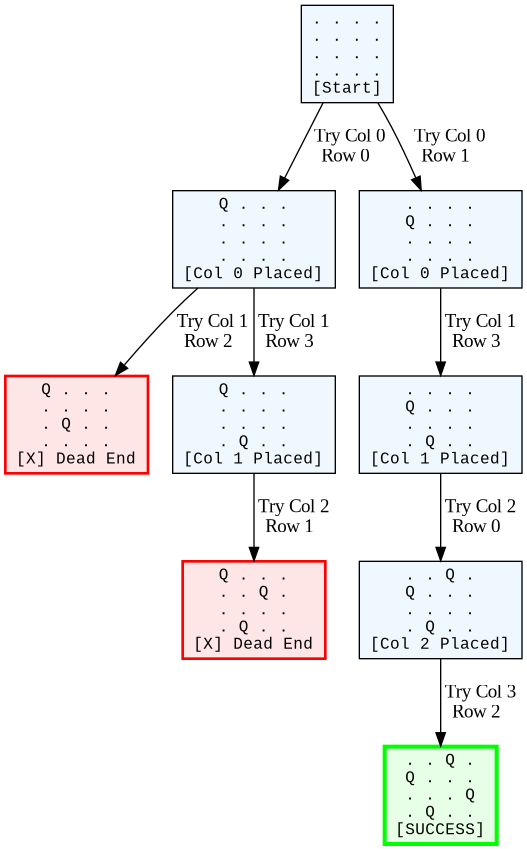

### Understanding the N-Queens Backtracking Tree

This tree visualizes the step-by-step decision-making process of the backtracking algorithm searching for a valid configuration of 4 queens on a 4x4 chessboard. Here is how to read and interpret the tree:

1. **Root Node (Start)**:
   - Represents an empty board ($4 \times 4$ grid of dots) before any queens are placed. This is the starting point of the algorithm.

2. **Decision Paths (Edges)**:
   - Each path from a parent to a child represents an attempt to place a queen. For example, `Try Col 0, Row 0` means the algorithm is placing a queen in the first column (Column 0) at the top row (Row 0).

3. **Node Types & Colors**:
   - **Blue Nodes (Normal Decisions)**: Represents a valid partial placement where the queens placed so far do not attack one another. The algorithm continues to branch forward from these nodes.
   - **Red Nodes ([X] Dead End)**: Represents a state where the algorithm reached a column but could not find a single safe row to place the next queen because of conflicts with already placed queens. Once a dead end is reached, the algorithm **backtracks** (goes back up the tree) to try different options.
   - **Green Node ([SUCCESS])**: Represents a leaf node where all 4 queens have been safely placed on the board without conflicts, successfully solving the puzzle.

### Understanding the Backtracking Tree

The visualization above clearly demonstrates how backtracking works in the N-Queens problem:

*   **Nodes:** Each node represents a state of the chessboard at a given recursive step. It shows where queens have been placed so far (`Q`) and empty squares (`.`).
*   **Edges:** The arrows represent the decisions made by the algorithm (e.g., "Try Col 0, Row 0"). Moving down an edge corresponds to a recursive call (`solveNQUtil(..., col + 1)`).
*   **Blue Nodes ([Start] / [Col X Placed]):** These represent valid partial solutions. The queens placed so far do not attack each other.
*   **Red Nodes ([X] Dead End):** These are the crucial backtracking moments. The algorithm reaches a column where *every* possible row is under attack by previously placed queens. Because no valid placement exists, the function returns without calling itself further. The search "backs up" to the previous column and tries the next safe row.
*   **Green Node ([SUCCESS]):** The algorithm has successfully placed all $N$ queens ($N=4$ in this case) without any conflicts. We found a valid solution!

This tree structure is generated dynamically based on the exact same logic used in our C++ backtracking code.

## Recursion and Backtracking Practice Exercises

Test your understanding of recursion and backtracking with these 5 structured exercises. Write out your code first before referring to the solutions below!

---

### Exercise 1: Recursive Power Function ($x^n$)
**Problem:** Write a recursive function `double power(double x, int n)` that calculates $x$ raised to the power $n$ ($x^n$). Optimize it using binary exponentiation ($O(\log n)$ complexity) to handle large values of $n$ efficiently (both positive and negative).

### Exercise 2: Count Occurrences of a Character in a String
**Problem:** Write a recursive function `int countChar(const string& str, char c, int index = 0)` that counts how many times a given character `c` appears in a string `str` without using any iterative loops (`for` or `while`).

### Exercise 3: Reverse a String Recursively
**Problem:** Implement a recursive function `string reverseString(const string& str)` that returns a completely reversed copy of the input string.

### Exercise 4: Permutations of a String (Backtracking)
**Problem:** Given a string of distinct characters, write a recursive backtracking function `void printPermutations(string str, int l, int r)` to print all unique rearrangements of its characters in any order.

### Exercise 5: Grid Paths / Robot Grid Walk
**Problem:** Imagine a robot sitting on the top-left corner of an $M \times N$ grid. The robot can only move either **down** or **right** at any point. Write a recursive function `int countPaths(int m, int n)` to calculate the total number of unique paths to reach the bottom-right corner of the grid.

## Exercise Solutions (C++)

Below are the implementations and explanations for the five exercises.

### Solution 1: Recursive Power Function (Binary Exponentiation)
```cpp
#include <iostream>
using namespace std;

double power(double x, long long n) {
    // Base Case
    if (n == 0) return 1.0;
    
    // Handle negative exponents
    if (n < 0) {
        x = 1.0 / x;
        n = -n;
    }
    
    double half = power(x, n / 2);
    
    // If n is even, x^n = x^(n/2) * x^(n/2)
    if (n % 2 == 0) {
        return half * half;
    }
    // If n is odd, x^n = x * x^(n/2) * x^(n/2)
    else {
        return x * half * half;
    }
}

int main() {
    cout << "2^10 = " << power(2, 10) << endl;
    cout << "5^-3 = " << power(5, -3) << endl;
    return 0;
}
```

### Solution 2: Count Occurrences of a Character
```cpp
#include <iostream>
#include <string>
using namespace std;

int countChar(const string& str, char c, int index = 0) {
    // Base Case: end of string reached
    if (index >= str.length()) {
        return 0;
    }
    
    // Recursive Case: check match at current index and add remaining count
    int match = (str[index] == c) ? 1 : 0;
    return match + countChar(str, c, index + 1);
}

int main() {
    string text = "recursion and backtracking";
    char target = 'r';
    cout << "Occurrences of '" << target << "' in \"" << text << "\": " << countChar(text, target) << endl;
    return 0;
}
```

### Solution 3: Reverse a String
```cpp
#include <iostream>
#include <string>
using namespace std;

string reverseString(const string& str) {
    // Base Case: empty or single character string
    if (str.length() <= 1) {
        return str;
    }
    
    // Recursive Case: reverse the substring from index 1 onward, then append the first character
    return reverseString(str.substr(1)) + str[0];
}

int main() {
    string input = "hello";
    cout << "Original: " << input << " | Reversed: " << reverseString(input) << endl;
    return 0;
}
```

### Solution 4: Permutations of a String
```cpp
#include <iostream>
#include <string>
using namespace std;

void printPermutations(string str, int l, int r) {
    // Base Case: Left index matches Right, one full permutation generated
    if (l == r) {
        cout << str << endl;
        return;
    }
    
    for (int i = l; i <= r; i++) {
        swap(str[l], str[i]);          // Make choice
        printPermutations(str, l + 1, r); // Recurse
        swap(str[l], str[i]);          // Backtrack
    }
}

int main() {
    string s = "ABC";
    cout << "Permutations of " << s << ":" << endl;
    printPermutations(s, 0, s.length() - 1);
    return 0;
}
```

### Solution 5: Grid Paths / Robot Grid Walk
```cpp
#include <iostream>
using namespace std;

int countPaths(int m, int n) {
    // Base Case: If we are at the border of the grid, only 1 direct path remains
    if (m == 1 || n == 1) {
        return 1;
    }
    
    // Recursive Case: sum of moving down (m-1, n) and moving right (m, n-1)
    return countPaths(m - 1, n) + countPaths(m, n - 1);
}

int main() {
    int M = 3, N = 3;
    cout << "Unique paths in a " << M << "x" << N << " grid: " << countPaths(M, N) << endl;
    return 0;
}
```